## 19. Homework Assignment

### 📝 Task: Superstore Profitability Prediction

**Dataset:** Superstore Sales

**Kaggle Link:** https://www.kaggle.com/datasets/himanshuuike/superstore-sales-dataset

**File:** `samplesuperstore.csv` (upload to `MyDrive/datasets/`)

**Target:** create `profit_class` from the profit margin (= Profit / Sales):

| Class | Rule |
|---|---|
| 0 – Loss | Profit < 0 |
| 1 – Low margin | margin < 0.25 |
| 2 – High margin | margin ≥ 0.25 |

---

### Tasks:

**Task 1: Load & Explore Data**
- Load the dataset from Google Drive
- Display first rows, `info()`, `describe()`

**Task 2: Clean Data**
- Create the `profit_class` target
- Keep features: Ship Mode, Segment, Region, Category, Sub-Category, Sales, Quantity, Discount
- Drop the `Profit` column

**Task 3: Preprocess**
- Encode text columns with `LabelEncoder`
- Stratified train/test split (80/20, `random_state=20`)

**Task 4: Train Models**
- Random Forest, Extra Trees, XGBoost, LightGBM, CatBoost, Stacking

**Task 5: Evaluate**
- Comparison table: accuracy, precision, recall, F1 (macro and weighted), ROC-AUC
- Classification report for every model

**Task 6: Visualize**
- Confusion matrix for every model
- ROC curve (one-vs-rest) + AUC for every model


---



In [79]:
# Install boosting libraries
!pip install xgboost lightgbm catboost -q

In [80]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing and model selection
from sklearn.preprocessing import LabelEncoder, label_binarize
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

# Ensemble models
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, StackingClassifier
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    roc_curve, auc, roc_auc_score,
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 20   # same seed everywhere -> reproducible results

# TASK 1: Load and Explore Data

In [81]:
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [82]:
DATA_PATH = '/content/drive/MyDrive/skill_morph/datasets/samplesuperstore.csv'
if not Path(DATA_PATH).exists():
    DATA_PATH = '/content/samplesuperstore.csv'  # alternative: upload directly to Colab

In [83]:
df = pd.read_csv(DATA_PATH, encoding='latin1')
print('Dataset shape:', df.shape)
display(df.head())

Dataset shape: (10194, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [84]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non-null  object 
 12  Region          10194 non-null  object 
 13  Product ID      10194 non-null  object 
 14  Category        10194 non-null  object 
 15  Sub-Category    10194 non-null  object 
 16  Product Name    10194 non-null  object 
 17  Sales           10194 non-null 

In [85]:
display(df.describe().round(2))

,Row ID,Sales,Quantity,Discount,Profit
count,10194.00,10194.00,10194.00,10194.00,10194.00
mean,5097.50,228.23,3.79,0.16,28.67
std,2942.90,619.91,2.23,0.21,232.47
min,1.00,0.44,1.00,0.00,-6599.98
25%,2549.25,17.22,2.00,0.00,1.76
50%,5097.50,53.91,3.00,0.20,8.69
75%,7645.75,209.50,5.00,0.20,29.30
max,10194.00,22638.48,14.00,0.80,8399.98


In [86]:
print('Missing values:')
print(df.isnull().sum())

Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


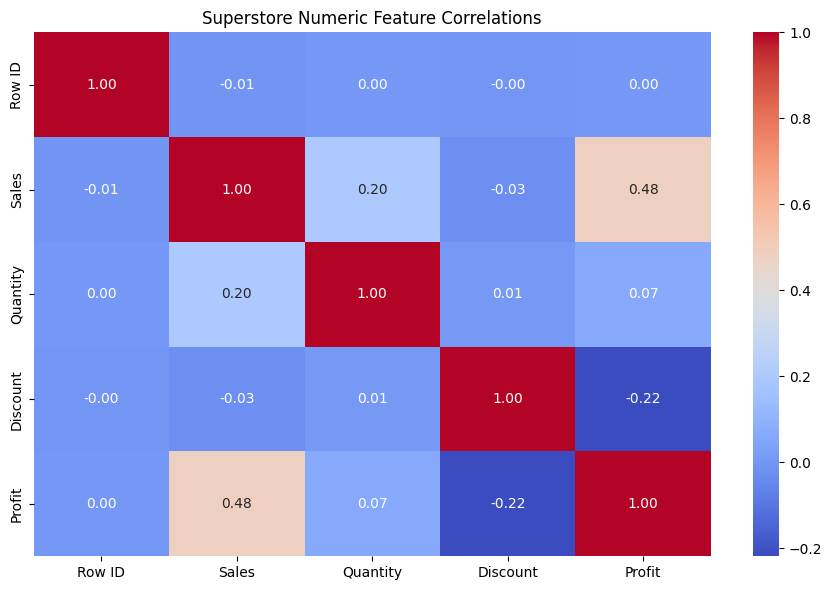

In [87]:
# Correlation heatmap of numeric columns
plt.figure(figsize=(9, 6))
sns.heatmap(df.select_dtypes(include='number').corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Superstore Numeric Feature Correlations')
plt.tight_layout()
plt.show()

# TASK 2: Clean Data

In [88]:
TARGET = "profit_class"
class_names = ["Loss", "Low margin", "High margin"]

# Reload df from DATA_PATH to make this cell re-runnable without KeyErrors
df = pd.read_csv(DATA_PATH, encoding='latin1')

# Create profit_class (0 = Loss, 1 = Low margin, 2 = High margin)
margin = df["Profit"] / df["Sales"].replace(0, np.nan)
df[TARGET] = np.select([df["Profit"] < 0, margin < 0.25], [0, 1], default=2)

features = ["Ship Mode", "Segment", "Region", "Category", "Sub-Category",
            "Sales", "Quantity", "Discount"]
df = df[features + [TARGET]].copy()  # Profit is excluded to prevent target leakage

for col in df.select_dtypes(exclude='number').columns:
    df[col] = df[col].fillna('unknown')
for col in df.select_dtypes(include='number').columns:
    df[col] = df[col].fillna(df[col].median())
df = df.drop_duplicates()
display(df.head())

,Ship Mode,Segment,Region,Category,Sub-Category,Sales,Quantity,Discount,profit_class
0,Standard Class,Consumer,Central,Office Supplies,Paper,16.448,2,0.2,2
1,Standard Class,Home Office,Central,Office Supplies,Binders,3.540,2,0.8,0
2,Standard Class,Home Office,Central,Office Supplies,Labels,11.784,3,0.2,2
3,Standard Class,Home Office,Central,Office Supplies,Storage,272.736,3,0.2,0
4,Standard Class,Consumer,East,Office Supplies,Art,19.536,3,0.2,2


In [89]:
print('Class distribution:')
print(df[TARGET].value_counts().sort_index())

Class distribution:
profit_class
0    1862
1    2435
2    5460
Name: count, dtype: int64


# TASK 3: Preprocess

In [90]:
# Features (X) and target (y)
X = df.drop(columns=[TARGET]).copy()
y = df[TARGET]

# Convert text columns to numbers (same as class notebook)
for col in X.select_dtypes(exclude="number").columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

display(X.head())

,Ship Mode,Segment,Region,Category,Sub-Category,Sales,Quantity,Discount
0,3,0,0,1,12,16.448,2,0.2
1,3,2,0,1,3,3.540,2,0.8
2,3,2,0,1,10,11.784,3,0.2
3,3,2,0,1,14,272.736,3,0.2
4,3,0,1,1,2,19.536,3,0.2


In [91]:
# Stratified 80/20 split keeps class proportions equal in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f"Training samples: {len(X_train)}")
print(f"Testing samples : {len(X_test)}")

Training samples: 7805
Testing samples : 1952


# TASK 4: Train Models

## Model 1: Random Forest

- Many decision trees trained on random samples of the data (**bagging**)
- Final prediction = majority vote of all trees

In [78]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)
print(f"Random Forest | accuracy = {accuracy_score(y_test, rf_pred):.4f}")


Random Forest | accuracy = 0.8412


## Model 2: Extra Trees

- Like Random Forest, but split points are chosen **randomly**
- Faster, and often less overfitting

In [92]:
# Extra Trees
et_model = ExtraTreesClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
et_model.fit(X_train, y_train)
et_pred = et_model.predict(X_test)
et_proba = et_model.predict_proba(X_test)
print(f"Extra Trees | accuracy = {accuracy_score(y_test, et_pred):.4f}")


Extra Trees | accuracy = 0.8202


## Model 3: XGBoost

- Trees are built **one after another**; each new tree fixes the errors of the previous ones (**boosting**)
- Great balance of speed and accuracy

In [93]:
# XGBoost
xgb_model = xgb.XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=5,
                              random_state=RANDOM_STATE)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_proba = xgb_model.predict_proba(X_test)
print(f"XGBoost | accuracy = {accuracy_score(y_test, xgb_pred):.4f}")


XGBoost | accuracy = 0.8571


## Model 4: LightGBM

- Boosting with fast, histogram-based trees
- Best for large datasets

In [94]:
# LightGBM
lgb_model = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=5,
                               random_state=RANDOM_STATE, verbose=-1)
lgb_model.fit(X_train, y_train)
lgb_pred = lgb_model.predict(X_test)
lgb_proba = lgb_model.predict_proba(X_test)
print(f"LightGBM | accuracy = {accuracy_score(y_test, lgb_pred):.4f}")


LightGBM | accuracy = 0.8658


## Model 5: CatBoost

- Boosting designed for categorical features
- Robust with little tuning

In [95]:
# CatBoost
cat_model = CatBoostClassifier(iterations=200, learning_rate=0.1, depth=5,
                               random_state=RANDOM_STATE, verbose=0)
cat_model.fit(X_train, y_train)
cat_pred = cat_model.predict(X_test).ravel().astype(int)
cat_proba = cat_model.predict_proba(X_test)
print(f"CatBoost | accuracy = {accuracy_score(y_test, cat_pred):.4f}")


CatBoost | accuracy = 0.8509


## Model 6: Stacking Ensemble

- The 5 models above are the **base models**
- A **meta-model** (Logistic Regression) learns how to combine their predictions

In [96]:
# Stacking: 5 base models + Logistic Regression as the meta-model
stack_model = StackingClassifier(
    estimators=[("rf", rf_model), ("et", et_model), ("xgb", xgb_model),
                ("lgb", lgb_model), ("cat", cat_model)],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=5,
)
stack_model.fit(X_train, y_train)
stack_pred = stack_model.predict(X_test)
stack_proba = stack_model.predict_proba(X_test)
print(f"Stacking | accuracy = {accuracy_score(y_test, stack_pred):.4f}")

Stacking | accuracy = 0.8555


# TASK 5: Evaluate


All models compared on the test set: accuracy, precision, recall, F1 score (macro and weighted average) and ROC-AUC.

In [97]:

models = {
    "Random Forest": (rf_pred, rf_proba),
    "Extra Trees":   (et_pred, et_proba),
    "XGBoost":       (xgb_pred, xgb_proba),
    "LightGBM":      (lgb_pred, lgb_proba),
    "CatBoost":      (cat_pred, cat_proba),
    "Stacking":      (stack_pred, stack_proba),
}

rows = []
for name, (pred, proba) in models.items():
    rows.append({
        "Model":                name,
        "Accuracy":             accuracy_score(y_test, pred),
        "Precision (macro)":    precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)":       recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)":           f1_score(y_test, pred, average="macro", zero_division=0),
        "Precision (weighted)": precision_score(y_test, pred, average="weighted", zero_division=0),
        "Recall (weighted)":    recall_score(y_test, pred, average="weighted", zero_division=0),
        "F1 (weighted)":        f1_score(y_test, pred, average="weighted", zero_division=0),
        "ROC-AUC":              roc_auc_score(y_test, proba, multi_class="ovr", average="macro", labels=[0, 1, 2]),
    })

results = pd.DataFrame(rows).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
best_model = results.iloc[0]["Model"]
display(results.round(4))


,Model,Accuracy,Precision (macro),Recall (macro),F1 (macro),Precision (weighted),Recall (weighted),F1 (weighted),ROC-AUC
0,LightGBM,0.8658,0.8450,0.8391,0.8419,0.8658,0.8658,0.8657,0.9668
1,XGBoost,0.8571,0.8373,0.8264,0.8315,0.8571,0.8571,0.8569,0.9662
2,Stacking,0.8555,0.8399,0.8217,0.8299,0.8567,0.8555,0.8555,0.9645
3,CatBoost,0.8509,0.8382,0.8146,0.8247,0.8537,0.8509,0.8512,0.9638
4,Random Forest,0.8412,0.8223,0.8108,0.8162,0.8414,0.8412,0.8411,0.9540
5,Extra Trees,0.8202,0.7969,0.7870,0.7917,0.8196,0.8202,0.8197,0.9344


In [98]:
print('Best model by macro F1:', best_model)

Best model by macro F1: LightGBM


In [99]:
# Classification report for every model
for name, (pred, proba) in models.items():
    print(f"\n{'=' * 15} {name} {'=' * 15}")
    print(classification_report(y_test, pred, labels=[0, 1, 2], target_names=class_names, zero_division=0))


=============== Random Forest ===============
              precision    recall  f1-score   support

        Loss       0.88      0.82      0.85       373
  Low margin       0.69      0.70      0.70       487
 High margin       0.89      0.91      0.90      1092

    accuracy                           0.84      1952
   macro avg       0.82      0.81      0.82      1952
weighted avg       0.84      0.84      0.84      1952


=============== Extra Trees ===============
              precision    recall  f1-score   support

        Loss       0.85      0.81      0.83       373
  Low margin       0.66      0.65      0.65       487
 High margin       0.88      0.90      0.89      1092

    accuracy                           0.82      1952
   macro avg       0.80      0.79      0.79      1952
weighted avg       0.82      0.82      0.82      1952


=============== XGBoost ===============
              precision    recall  f1-score   support

        Loss       0.88      0.83      0.85       

# TASK 6: Visualize

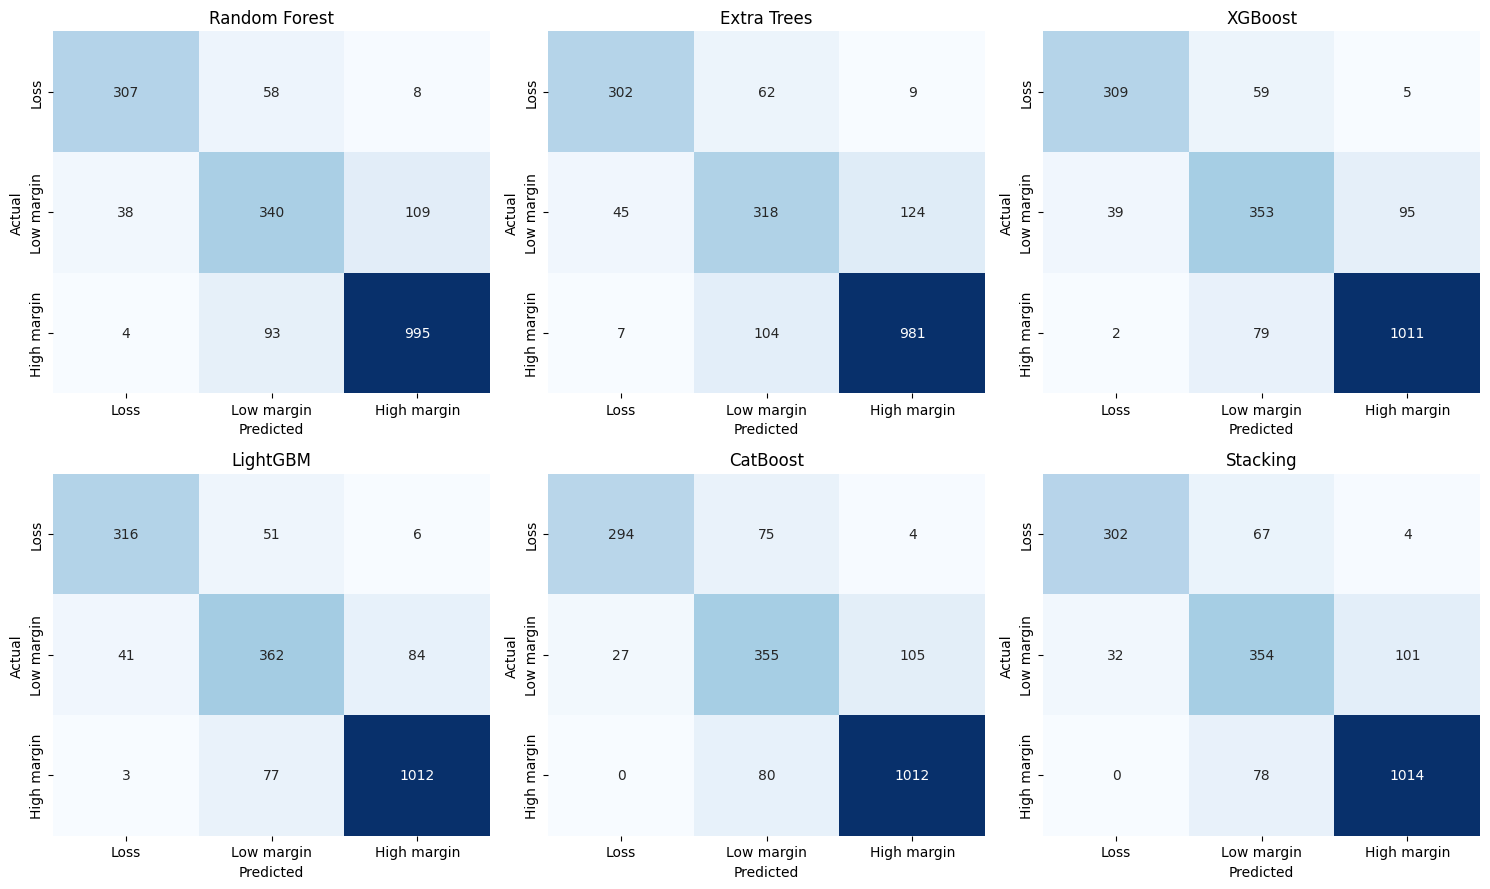

In [100]:
# TASK 6: Visualize
# Confusion matrix for every model
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, (pred, proba)) in zip(axes.ravel(), models.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

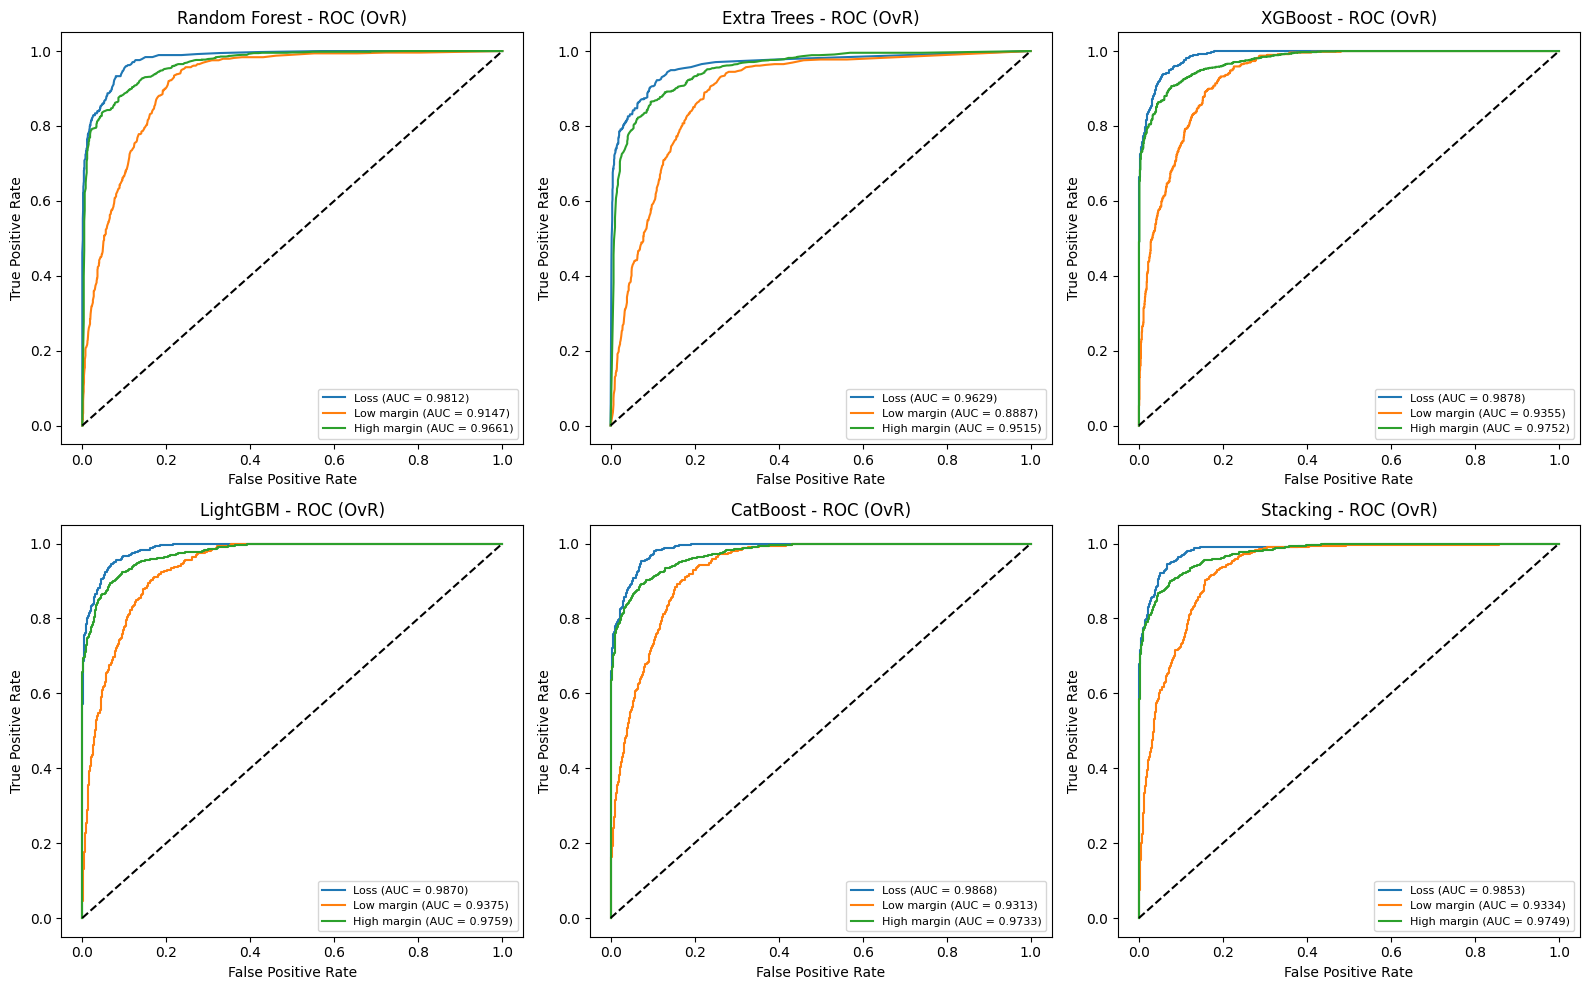

In [101]:

# One-vs-rest ROC curves and AUC for all six models (3 classes)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (name, (pred, proba)) in zip(axes.ravel(), models.items()):
    for i, class_name in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], proba[:, i])
        ax.plot(fpr, tpr, label=f"{class_name} (AUC = {auc(fpr, tpr):.4f})")
    ax.plot([0, 1], [0, 1], "k--")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(f"{name} - ROC (OvR)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()